<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/U3/Practica_1/AD_U3_Pr%C3%A1ctica1_DelgadoRam%C3%ADrez.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

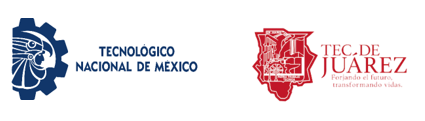

#**INSTITUTO TECNOLOGICO DE CIUDAD JUAREZ**
**Ciencia y analítica de datos**
*   NOMBRE: María Fernanda Delgado Ramírez
*   NO. CONTROL: 23111480

 **UNIDAD 3**

Árbol de decisión y Random Forest

# Exploración de las estadísticas de equipos de la NFL, 2003 a 2023

Aquí se analiza el archivo `team_stats_2003_2023.csv`. El archivo tiene las estadísticas de cada equipo en cada temporada: cuántos partidos ganó, cuántos puntos anotó, cuántas yardas avanzó por pase y por carrera, y cuántas penalizaciones recibió. Antes de hacer cualquier análisis, primero se quiere saber qué datos hay, de qué tipo son y si les falta información.

## **¿Qué se quiere predecir?**

Con estos datos se quiere predecir el rendimiento de un equipo en una temporada.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### **Carga del archivo**

Se cargan las librerías que se van a usar y se abre el archivo CSV en una tabla de pandas llamada `nfl_df`.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
nfl_df=pd.read_csv('/content/drive/MyDrive/Colab Notebooks/NFL/team_stats_2003_2023.csv')

### **Tamaño de la tabla**

Contamos cuántas filas y cuántas columnas tiene la tabla, donde cada fila es un equipo en una temporada.

In [ ]:
print(f"Filas: {nfl_df.shape[0]}")
print(f"Columnas: {nfl_df.shape[1]}")
print(f"Periodo: {nfl_df['year'].min()} a {nfl_df['year'].max()}")
print(f"Temporadas: {nfl_df['year'].nunique()}")
print(f"Equipos distintos: {nfl_df['team'].nunique()}")

Filas: 672
Columnas: 35
Periodo: 2003 a 2023
Temporadas: 21
Equipos distintos: 37


Aqui estan los tipos de datos

###**Primeras y últimas filas**

Se muestran algunas filas del inicio y del final de la tabla para ver cómo se ven los datos y cómo están ordenados.

In [ ]:
pd.set_option("display.max_columns", None)
nfl_df.head()

,year,team,wins,losses,win_loss_perc,points,points_opp,points_diff,mov,g,total_yards,plays_offense,yds_per_play_offense,turnovers,fumbles_lost,first_down,pass_cmp,pass_att,pass_yds,pass_td,pass_int,pass_net_yds_per_att,pass_fd,rush_att,rush_yds,rush_td,rush_yds_per_att,rush_fd,penalties,penalties_yds,pen_fd,score_pct,turnover_pct,exp_pts_tot,ties
0,2003,New England Patriots,14,2,0.875,348,238,110,6.9,16,5039,1042,4.8,24,11,294,320,537,3432,23,13,6.0,177,473,1607,9,3.4,91,111,998,26,27.9,11.3,-136.51,NaN
1,2003,Miami Dolphins,10,6,0.625,311,261,50,3.1,16,4609,968,4.8,34,15,266,257,450,2792,17,19,5.8,145,487,1817,14,3.7,99,103,913,22,28.1,17.2,-177.92,NaN
2,2003,Buffalo Bills,6,10,0.375,243,279,-36,-2.3,16,4348,980,4.4,34,17,268,293,502,2684,11,17,4.9,150,427,1664,13,3.9,96,106,891,22,21.9,17.6,-230.07,NaN
3,2003,New York Jets,6,10,0.375,283,299,-16,-1.0,16,4951,936,5.3,20,6,274,312,496,3316,20,14,6.3,181,409,1635,8,4.0,78,69,550,15,32.4,11.8,-107.89,NaN
4,2003,Baltimore Ravens,10,6,0.625,391,281,110,6.9,16,4929,1009,4.9,38,19,259,217,415,2255,16,19,4.9,121,552,2674,18,4.8,115,126,970,23,31.8,16.6,-220.50,NaN


In [ ]:
nfl_df.tail()

,year,team,wins,losses,win_loss_perc,points,points_opp,points_diff,mov,g,total_yards,plays_offense,yds_per_play_offense,turnovers,fumbles_lost,first_down,pass_cmp,pass_att,pass_yds,pass_td,pass_int,pass_net_yds_per_att,pass_fd,rush_att,rush_yds,rush_td,rush_yds_per_att,rush_fd,penalties,penalties_yds,pen_fd,score_pct,turnover_pct,exp_pts_tot,ties
667,2023,Carolina Panthers,2,15,0.118,236,416,-180,-10.6,17,4510,1096,4.1,20,10,297,350,586,2741,13,10,4.2,150,445,1769,7,4.0,111,103,845,36,25.0,11.1,-135.03,NaN
668,2023,San Francisco 49ers,12,5,0.706,491,298,193,11.4,17,6773,1024,6.6,18,6,383,336,491,4384,33,12,8.4,207,499,2389,27,4.8,147,101,933,29,45.3,10.1,231.48,NaN
669,2023,Los Angeles Rams,10,7,0.588,404,377,27,1.6,17,6108,1094,5.6,18,5,351,361,583,4063,26,13,6.6,206,477,2045,18,4.3,110,89,720,35,41.1,9.2,133.32,NaN
670,2023,Seattle Seahawks,9,8,0.529,364,402,-38,-2.2,17,5490,995,5.5,17,5,317,371,575,3910,23,12,6.4,189,382,1580,11,4.1,93,111,954,35,38.8,8.4,62.33,NaN
671,2023,Arizona Cardinals,4,13,0.235,330,455,-125,-7.4,17,5509,1068,5.2,18,6,330,355,555,3144,18,12,5.3,173,471,2365,17,5.0,127,101,859,30,35.0,9.4,-2.99,NaN


### **Columnas y tipos de datos**

Aqui revisamos cuántos datos tiene cada columna y de qué tipo son. La columna `team` tiene texto y las demás con las que tienen números.

In [ ]:
nfl_df.info()
# Aqui podemos notar que en team pertenece al tipo de dato object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 672 entries, 0 to 671
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  672 non-null    int64  
 1   team                  672 non-null    object 
 2   wins                  672 non-null    int64  
 3   losses                672 non-null    int64  
 4   win_loss_perc         672 non-null    float64
 5   points                672 non-null    int64  
 6   points_opp            672 non-null    int64  
 7   points_diff           672 non-null    int64  
 8   mov                   352 non-null    float64
 9   g                     672 non-null    int64  
 10  total_yards           672 non-null    int64  
 11  plays_offense         672 non-null    int64  
 12  yds_per_play_offense  672 non-null    float64
 13  turnovers             672 non-null    int64  
 14  fumbles_lost          672 non-null    int64  
 15  first_down            6

### **Qué significa cada columna**

Las columnas se agrupan según lo que miden.

| Grupo | Columna | Qué mide |
|---|---|---|
| Datos generales | `year` | Año de la temporada |
| Datos generales | `team` | Nombre del equipo |
| Resultados | `wins`, `losses`, `ties` | Partidos ganados, perdidos y empatados |
| Resultados | `win_loss_perc` | Proporción de partidos ganados |
| Resultados | `g` | Partidos jugados en la temporada |
| Puntos | `points`, `points_opp` | Puntos que anotó el equipo y puntos que le anotaron |
| Puntos | `points_diff` | Puntos anotados menos puntos recibidos |
| Puntos | `mov` | Diferencia promedio de puntos por partido |
| Ataque en general | `total_yards`, `plays_offense`, `yds_per_play_offense` | Yardas avanzadas, jugadas de ataque y yardas por jugada |
| Ataque en general | `first_down` | Veces que el equipo logró un primer intento |
| Ataque en general | `turnovers`, `fumbles_lost` | Veces que el equipo perdió el balón y fumbles perdidos |
| Pase | `pass_cmp`, `pass_att`, `pass_yds`, `pass_td`, `pass_int` | Pases completos, pases intentados, yardas, touchdowns e intercepciones |
| Pase | `pass_net_yds_per_att`, `pass_fd` | Yardas netas por pase intentado y primeros intentos logrados por pase |
| Carrera | `rush_att`, `rush_yds`, `rush_td` | Veces que se corrió con el balón, yardas avanzadas y touchdowns |
| Carrera | `rush_yds_per_att`, `rush_fd` | Yardas por cada carrera y primeros intentos logrados corriendo |
| Penalizaciones | `penalties`, `penalties_yds`, `pen_fd` | Penalizaciones recibidas, yardas perdidas y primeros intentos que se dieron al rival por penalización |
| Otras medidas | `score_pct`, `turnover_pct` | Porcentaje de series de ataque que terminan en puntos y porcentaje que terminan en pérdida del balón |
| Otras medidas | `exp_pts_tot` | Puntos que se esperaba que el ataque aportara en total |

### **Datos faltantes**

Cuenta cuántos datos vacíos tiene cada columna y el porcentaje de la tabla que representan.

In [ ]:
nulos = nfl_df.isna().sum()
porcentaje = (nulos / len(nfl_df) * 100).round(2)
resumen_nulos = pd.DataFrame({"nulos": nulos, "porcentaje": porcentaje})
resumen_nulos[resumen_nulos["nulos"] > 0]

,nulos,porcentaje
mov,320,47.62
ties,352,52.38


In [ ]:
print("Filas con al menos un nulo:", nfl_df.isna().any(axis=1).sum())
print("Filas con nulo en mov y en ties a la vez:", (nfl_df["mov"].isna() & nfl_df["ties"].isna()).sum())

Filas con al menos un nulo: 672
Filas con nulo en mov y en ties a la vez: 0


Solo las columnas `mov` y `ties` tienen datos vacíos, y las otras 33 columnas están completas. Los vacíos de una columna coinciden con los años en que la otra sí tiene datos, así que cada fila tiene exactamente un dato vacío.

In [ ]:
nfl_df["ties_calc"] = nfl_df["g"] - nfl_df["wins"] - nfl_df["losses"]
nfl_df["mov_calc"] = (nfl_df["points_diff"] / nfl_df["g"]).round(1)

print("ties coincide con el cálculo:", (nfl_df["ties"].dropna() == nfl_df.loc[nfl_df["ties"].notna(), "ties_calc"]).all())
print("mov coincide con el cálculo:", ((nfl_df["mov"].dropna() - nfl_df.loc[nfl_df["mov"].notna(), "mov_calc"]).abs() < 0.11).all())
print("Años con empates:", sorted(nfl_df.loc[nfl_df["ties_calc"] > 0, "year"].unique()))

ties coincide con el cálculo: True
mov coincide con el cálculo: True
Años con empates: [np.int64(2008), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2016), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022)]


La columna `mov` es la diferencia promedio de puntos por partido y se calcula como `points_diff` entre `g`. La columna `ties` es el número de partidos empatados y se calcula como `g` menos `wins` menos `losses`. Los datos vacíos de `ties` corresponden a años sin empates, así que equivalen a 0. Los datos vacíos de `mov` se pueden reconstruir con la fórmula anterior, por lo que no se pierde información.

### **Equipos y temporadas**

Contamos cuántos registros hay por año y cuántas veces aparece cada nombre de equipo. Hay más nombres que equipos reales, porque algunos cambiaron de nombre o de ciudad durante estos años.

In [ ]:
nfl_df.groupby("year").size()

,0
year,
2003,32
2004,32
2005,32
2006,32
2007,32
2008,32
2009,32
2010,32
2011,32


In [ ]:
nfl_df["team"].value_counts().sort_index()

,count
team,
Arizona Cardinals,21
Atlanta Falcons,21
Baltimore Ravens,21
Buffalo Bills,21
Carolina Panthers,21
Chicago Bears,21
Cincinnati Bengals,21
Cleveland Browns,21
Dallas Cowboys,21


Los nombres con menos de 21 registros corresponden a franquicias que cambiaron de identidad, por ejemplo Oakland Raiders y Las Vegas Raiders, San Diego Chargers y Los Angeles Chargers, o St. Louis Rams y Los Angeles Rams. Washington aparece con tres nombres. Asi que cuando trabajemos con el dataset es necesario unificar estos nombres.

### **Filas repetidas y partidos por temporada**

Se revisa que no haya filas repetidas y que cada equipo aparezca una sola vez por año. También se revisa cuántos partidos se jugaron en cada temporada.

In [ ]:
print("Filas duplicadas:", nfl_df.duplicated().sum())
print("Duplicados por año y equipo:", nfl_df.duplicated(subset=["year", "team"]).sum())
print()
print(nfl_df.groupby("year")["g"].max().loc[lambda s: s != 16])

Filas duplicadas: 0
Duplicados por año y equipo: 0

year
2021    17
2022    17
2023    17
Name: g, dtype: int64


## Rendimiento de un equipo a lo largo de las temporadas

Esta gráfica sirve como ejemplo de lo que se quiere predecir más adelante, que es el rendimiento de un equipo en una temporada. En el caso de los 49ers, el número de victorias va desde 2 en 2004 hasta 13 en 2011, por lo que el rendimiento de un mismo equipo puede cambiar mucho de un año a otro.


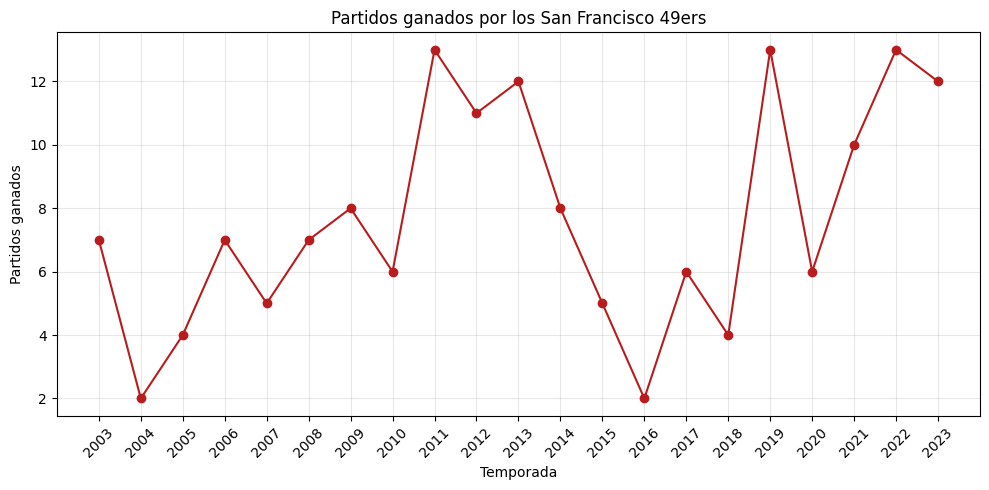

In [ ]:
import matplotlib.pyplot as plt

niners = nfl_df[nfl_df["team"] == "San Francisco 49ers"]

plt.figure(figsize=(10, 5))
plt.plot(niners["year"], niners["wins"], marker="o", color="#b91c1c")
plt.title("Partidos ganados por los San Francisco 49ers")
plt.xlabel("Temporada")
plt.ylabel("Partidos ganados")
plt.xticks(niners["year"], rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **Árbol de decisión y bosque aleatorio**

Hasta aquí se revisaron los datos. Ahora se construyen dos modelos para predecir el rendimiento de un equipo en una temporada: un **árbol de decisión** y un **bosque aleatorio**. Los pasos son los mismos del ejemplo visto en clase con la base iris, adaptados a los datos de la NFL:

1. Definir qué se quiere predecir y con qué variables.
2. Dividir los datos en entrenamiento, validación y prueba.
3. Entrenar un árbol de decisión, revisar sus errores y controlar el sobreentrenamiento (poda).
4. Entrenar un bosque aleatorio y comparar su desempeño con el del árbol.
5. Evaluar el mejor modelo una sola vez con el conjunto de prueba.

Como el objetivo es clasificar, se usan `DecisionTreeClassifier` y `RandomForestClassifier` de scikit-learn.

### **Variable que se quiere predecir**

En el ejemplo de iris, el modelo clasifica cada flor en una de tres especies. Aquí se hará algo parecido: cada equipo en cada temporada se clasifica en uno de tres niveles de rendimiento, según la proporción de partidos ganados (`win_loss_perc`).

| Rendimiento | Proporción de victorias | Equivale aproximadamente a |
|---|---|---|
| Bajo | 0.40 o menos | 6 victorias o menos en 16 partidos |
| Medio | Más de 0.40 y hasta 0.60 | De 7 a 9 victorias en 16 partidos |
| Alto | Más de 0.60 | 10 victorias o más en 16 partidos |

Se crea la columna `rendimiento` en la tabla y se revisa cuántos registros hay en cada nivel. Es importante que los tres niveles tengan una cantidad parecida de registros, para que el modelo no favorezca a uno solo.

In [ ]:
def clasificar_rendimiento(proporcion):
    if proporcion <= 0.40:
        return "Bajo"
    elif proporcion <= 0.60:
        return "Medio"
    else:
        return "Alto"

nfl_df["rendimiento"] = nfl_df["win_loss_perc"].apply(clasificar_rendimiento)

clases = ["Bajo", "Medio", "Alto"]   # el orden de la lista define la clase 0, 1 y 2
nfl_df["rendimiento"].value_counts().reindex(clases)

rendimiento
Bajo     210
Medio    241
Alto     221
Name: count, dtype: int64

### **Variables de entrada**

No todas las columnas se pueden usar para predecir. Se excluyen las siguientes:

- **Columnas que ya contienen el resultado:** `wins`, `losses`, `ties`, `win_loss_perc` y `g`. Si se dejaran, el modelo solo leería la respuesta en lugar de aprender de las estadísticas del equipo.
- **Columnas calculadas a partir de los puntos:** `points_diff` y `mov`, que dependen directamente de los puntos anotados y recibidos y casi determinan quién ganó. También se excluyen `ties_calc` y `mov_calc`, que se agregaron antes en este cuaderno.
- **Identificadores:** `team` y `year`. Son nombres y fechas, no estadísticas de juego, y el nombre del equipo ni siquiera es un número.

Las 26 columnas restantes son estadísticas de ataque, pases, carreras, penalizaciones y puntos. Los árboles no necesitan que las variables estén en la misma escala, por lo que no hace falta normalizarlas.

In [ ]:
columnas_excluidas = ["year", "team", "wins", "losses", "ties", "win_loss_perc", "g",
                      "points_diff", "mov", "ties_calc", "mov_calc", "rendimiento"]

variables = [c for c in nfl_df.columns if c not in columnas_excluidas]

X = nfl_df[variables]                                                   # datos de entrada
y = nfl_df["rendimiento"].map({nombre: i for i, nombre in enumerate(clases)})   # etiquetas: 0, 1 o 2

print(X.shape)
print(y.shape)
print(variables)

(672, 26)
(672,)
['points', 'points_opp', 'total_yards', 'plays_offense', 'yds_per_play_offense', 'turnovers', 'fumbles_lost', 'first_down', 'pass_cmp', 'pass_att', 'pass_yds', 'pass_td', 'pass_int', 'pass_net_yds_per_att', 'pass_fd', 'rush_att', 'rush_yds', 'rush_td', 'rush_yds_per_att', 'rush_fd', 'penalties', 'penalties_yds', 'pen_fd', 'score_pct', 'turnover_pct', 'exp_pts_tot']


Para tener una idea de cómo se comportan los datos, se calcula el promedio de algunas variables en cada nivel de rendimiento. Se espera que los equipos de rendimiento alto anoten más puntos, reciban menos y pierdan menos veces el balón.

In [ ]:
nfl_df.groupby("rendimiento")[["points", "points_opp", "turnovers", "pass_yds", "rush_yds", "penalties"]].mean().round(1).reindex(clases)

,points,points_opp,turnovers,pass_yds,rush_yds,penalties
rendimiento,,,,,,
Bajo,295.2,402.0,28.6,3340.6,1686.4,105.0
Medio,357.7,360.6,24.6,3655.3,1848.5,100.0
Alto,420.0,315.3,21.1,3837.8,1997.8,99.8


### **División de los datos: entrenamiento, validación y prueba**

Igual que en el ejemplo, los datos se dividen en tres conjuntos de 60 %, 20 % y 20 %:

- **Entrenamiento:** sirve para que el modelo aprenda.
- **Validación:** sirve para comparar modelos y ajustar sus hiperparámetros.
- **Prueba:** se usa al final, una sola vez, para conocer el desempeño real del modelo elegido.

Se agrega el argumento `stratify`, que mantiene en cada conjunto la misma proporción de equipos con rendimiento bajo, medio y alto.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [ ]:
X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=.2, shuffle=True, random_state=1, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=.25, shuffle=True, random_state=1, stratify=y_tv)

print('Tamaño del conjunto de entrenamiento:', X_train.shape)
print('Tamaño del conjunto de validación:', X_val.shape)
print('Tamaño del conjunto de prueba:', X_test.shape)

Tamaño del conjunto de entrenamiento: (402, 26)
Tamaño del conjunto de validación: (135, 26)
Tamaño del conjunto de prueba: (135, 26)


## **Parte 1: Árbol de decisión**

Un árbol de decisión clasifica haciendo preguntas sencillas sobre las variables, por ejemplo "¿el equipo anotó más de 400 puntos?". Según la respuesta, el registro pasa por una rama u otra hasta llegar a una hoja, que da la clase predicha.

Primero se entrena un árbol con los hiperparámetros predeterminados, es decir, sin ninguna limitación. Se mide su exactitud (*accuracy*) en entrenamiento y en validación. La exactitud en entrenamiento solo sirve para detectar sobreentrenamiento; el modelo se evalúa con el conjunto de validación.

In [ ]:
modeloDT = DecisionTreeClassifier(random_state=1)   # hiperparámetros predeterminados
clf_dt = modeloDT.fit(X_train, y_train)

print('Exactitud en el conjunto de entrenamiento: %.2f' % clf_dt.score(X_train, y_train))

pred_dt = clf_dt.predict(X_val)
print('Exactitud en el conjunto de validación: %.2f' % clf_dt.score(X_val, y_val))

Exactitud en el conjunto de entrenamiento: 1.00
Exactitud en el conjunto de validación: 0.70


El árbol sin límites acierta en el 100 % de los registros de entrenamiento, pero solo en el 70 % de los de validación. Esa diferencia de 30 puntos indica **sobreentrenamiento**: el árbol memorizó los datos con los que aprendió y generaliza peor con datos nuevos. Aun así, el 70 % es mucho mejor que el 33 % que se obtendría al elegir una clase al azar entre tres.

La **matriz de confusión** muestra cómo se equivoca el modelo. Los renglones son las clases reales y las columnas son las clases predichas. Las clases van en el orden 0 = Bajo, 1 = Medio y 2 = Alto. Los valores de la diagonal son los aciertos.

[[34  8  0]
 [11 29  8]
 [ 0 13 32]]


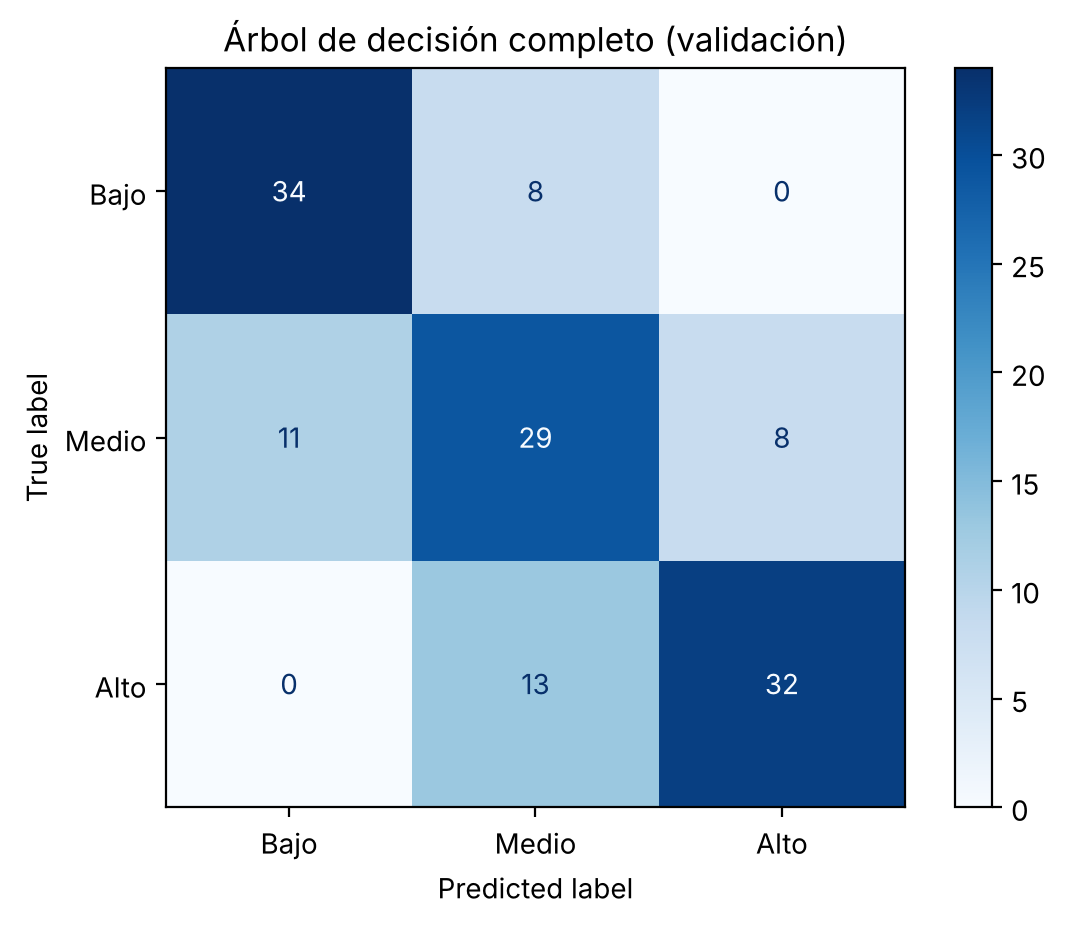

In [ ]:
print(confusion_matrix(y_val, pred_dt))   # (renglones: real, columnas: predicción)

ConfusionMatrixDisplay.from_predictions(y_val, pred_dt, display_labels=clases, cmap="Blues")
plt.title("Árbol de decisión completo (validación)")
plt.show()

Al revisar la matriz se observa que de 135 equipos el árbol acertó en 95 (34 bajos, 29 medios y 32 altos). Los errores casi siempre ocurren entre niveles vecinos: un equipo bajo se confunde con uno medio, o uno medio con uno alto. En ningún caso confundió un equipo de rendimiento bajo con uno alto, ni al revés. Esto tiene sentido, porque el nivel medio es el que está en medio y por eso es el más difícil de distinguir.

### **Visualización del árbol**

Se dibuja el árbol entrenado. Como el árbol completo es muy grande, solo se muestran los primeros tres niveles. En cada cuadro aparece la pregunta que se hace, la cantidad de registros (`samples`), cuántos hay de cada clase (`value`) y la clase que predomina (`class`). El color indica la clase: entre más intenso, más puro es el grupo.

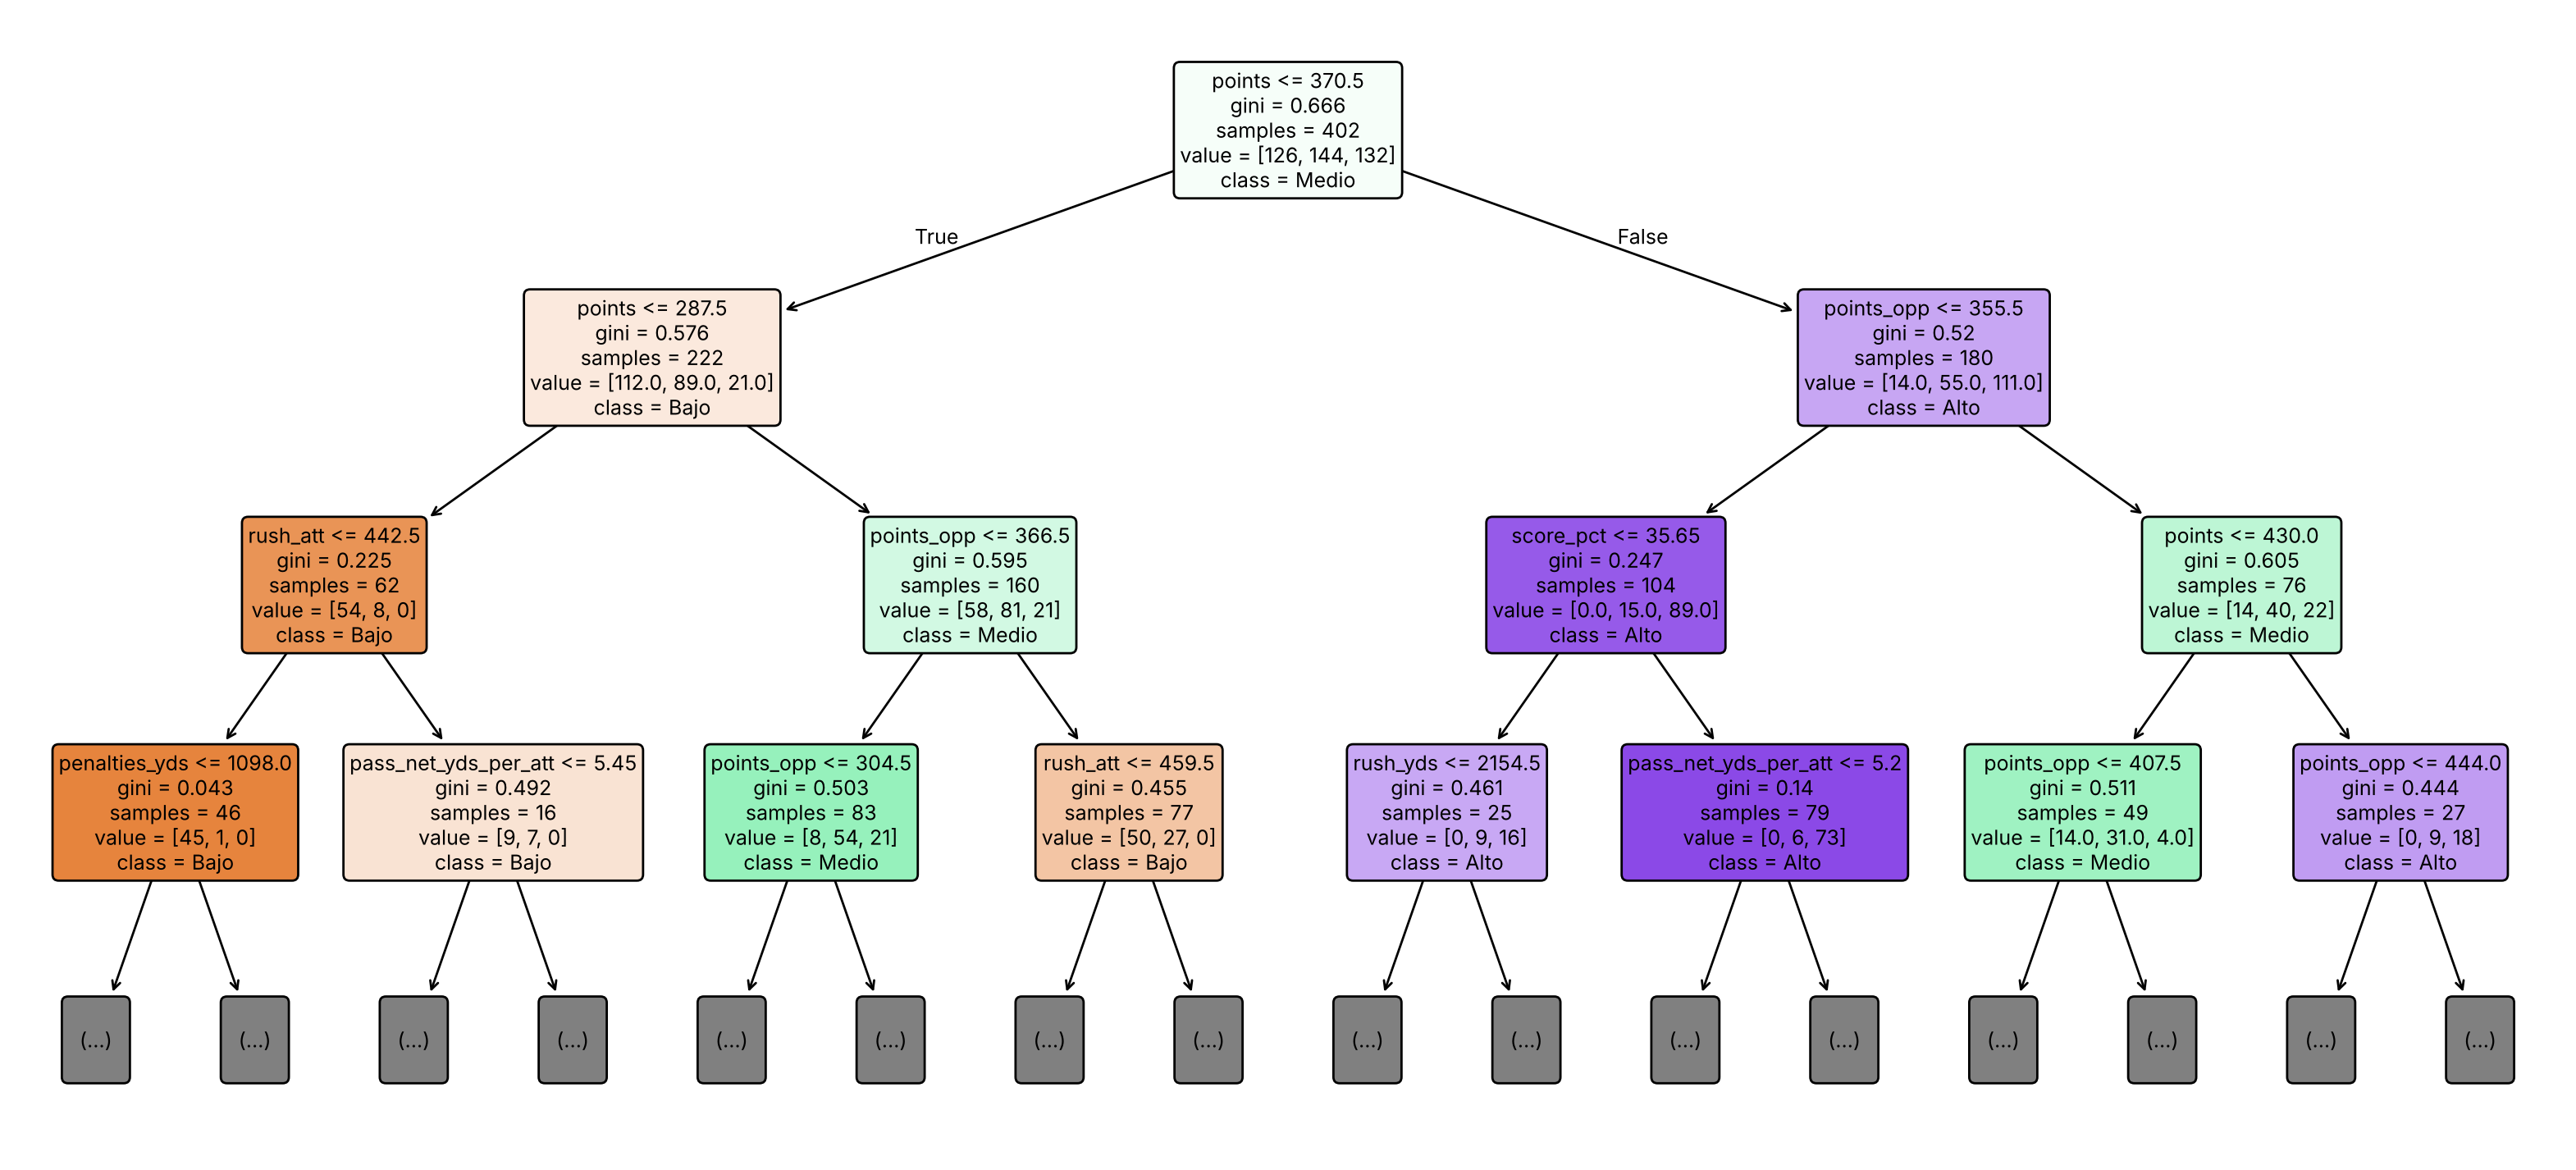

In [ ]:
plt.figure(figsize=(20, 9))
plot_tree(clf_dt, max_depth=3, feature_names=variables, class_names=clases,
          filled=True, rounded=True, fontsize=9)
plt.show()

### **Poda (pruning) y sobreentrenamiento**

Un árbol sin límites sigue dividiendo hasta memorizar los datos de entrenamiento, y por eso le va peor con datos nuevos. Para evitarlo se limita su crecimiento con estos hiperparámetros:

- `max_depth`: profundidad máxima del árbol. Entre más grande, mayor sobreentrenamiento.
- `min_samples_split`: mínimo de registros que debe tener un nodo para poder dividirse. Entre menor, mayor sobreentrenamiento.
- `min_samples_leaf`: mínimo de registros que debe tener cada hoja. Entre menor, mayor sobreentrenamiento.
- `ccp_alpha`: parámetro de poda por costo-complejidad. Entre mayor, más ramas se eliminan.

Para elegir la profundidad se entrenan árboles con profundidades de 1 a 15 y se comparan la exactitud en entrenamiento y en validación.

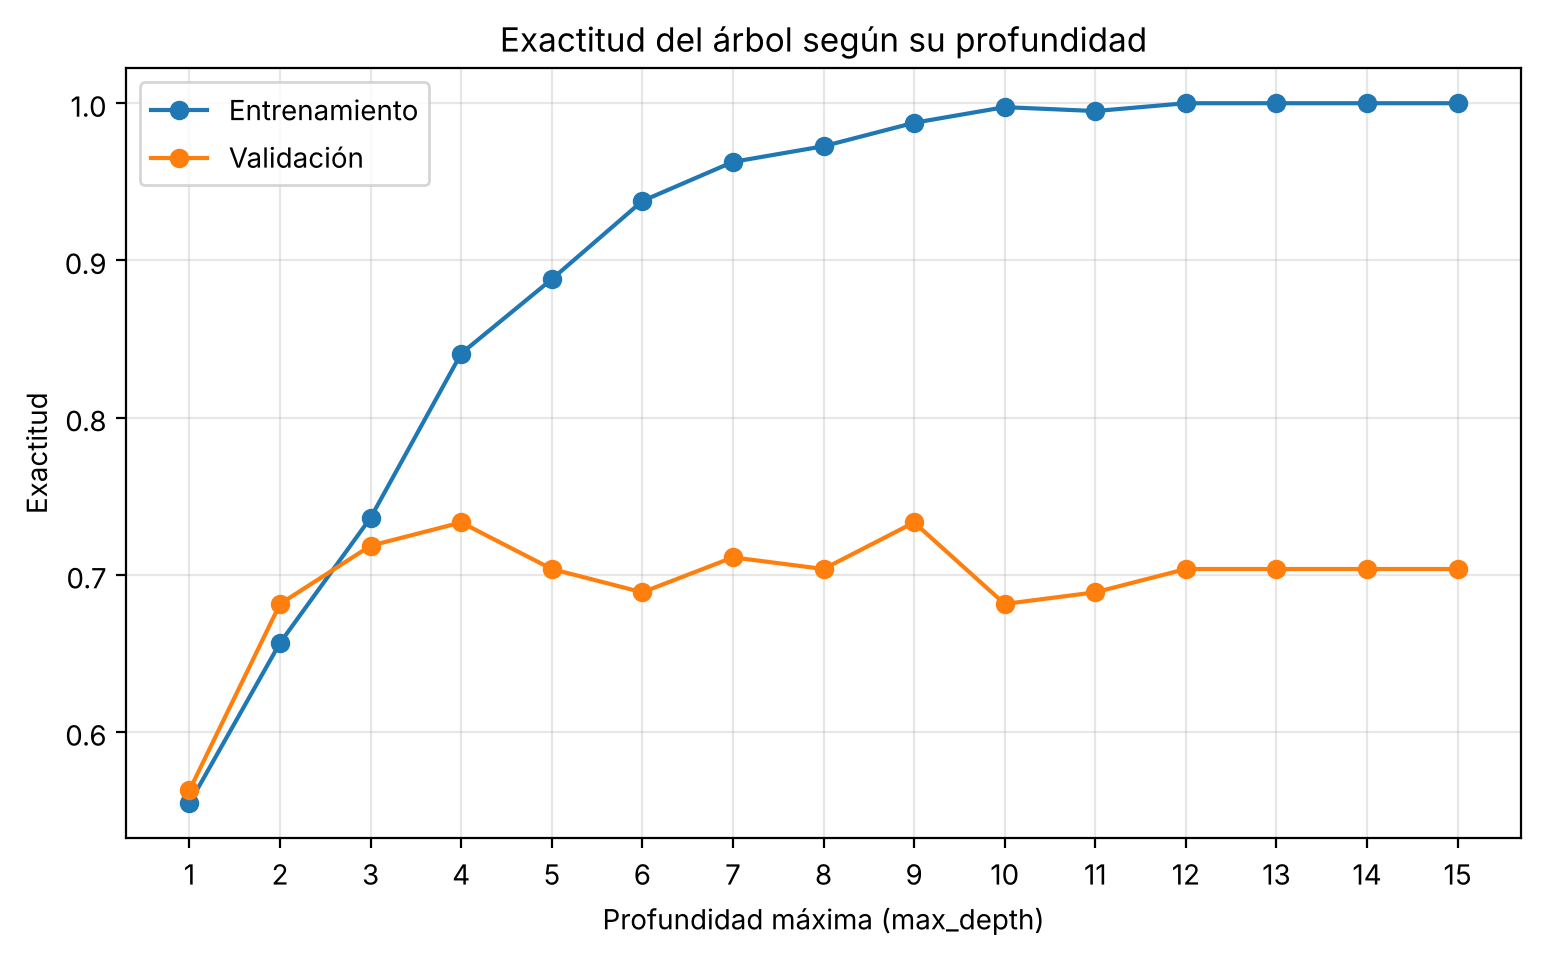

In [ ]:
profundidades = range(1, 16)
acc_train, acc_val = [], []

for d in profundidades:
    modelo = DecisionTreeClassifier(max_depth=d, random_state=1).fit(X_train, y_train)
    acc_train.append(modelo.score(X_train, y_train))
    acc_val.append(modelo.score(X_val, y_val))

plt.figure(figsize=(9, 5))
plt.plot(profundidades, acc_train, marker="o", label="Entrenamiento")
plt.plot(profundidades, acc_val, marker="o", label="Validación")
plt.title("Exactitud del árbol según su profundidad")
plt.xlabel("Profundidad máxima (max_depth)")
plt.ylabel("Exactitud")
plt.xticks(profundidades)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

En la gráfica se ve que la exactitud en entrenamiento sube hasta quedar cerca de 1.00 a partir de la profundidad 10, mientras que la de validación se queda cerca de 0.70 y no mejora. Con una profundidad de 3 las dos curvas están muy cerca (0.74 y 0.72), así que el árbol no memoriza y generaliza bien. Por eso se elige `max_depth=3`, que además da un árbol pequeño y fácil de interpretar. A este valor se agregan `min_samples_leaf=10` y `ccp_alpha=0.005`; el hiperparámetro `min_samples_split` se deja con su valor predeterminado.

In [ ]:
modeloDT_podado = DecisionTreeClassifier(max_depth=3,
                                         min_samples_leaf=10,
                                         ccp_alpha=0.005,
                                         random_state=1)
clf_dt_podado = modeloDT_podado.fit(X_train, y_train)

pred_dt_podado = clf_dt_podado.predict(X_val)
print('Exactitud en el conjunto de entrenamiento: %.2f' % clf_dt_podado.score(X_train, y_train))
print('Exactitud en el conjunto de validación: %.2f' % clf_dt_podado.score(X_val, y_val))
print()
print(confusion_matrix(y_val, pred_dt_podado))

Exactitud en el conjunto de entrenamiento: 0.74
Exactitud en el conjunto de validación: 0.72

[[38  4  0]
 [14 25  9]
 [ 0 11 34]]


Con la poda, la diferencia entre entrenamiento (0.74) y validación (0.72) bajó de 30 puntos a solo 2, y la exactitud en validación subió de 0.70 a 0.72. Es decir, el árbol podado es más sencillo y además generaliza mejor. La matriz de confusión muestra que el nivel medio sigue siendo el más difícil: solo 25 de los 48 equipos medios se clasificaron bien.

En el diagrama se puede leer el razonamiento del modelo. Primero pregunta cuántos puntos anotó el equipo y después cuántos puntos recibió. Por ejemplo, los equipos que anotaron más de 370 puntos y recibieron 355 o menos se clasifican como de rendimiento alto.

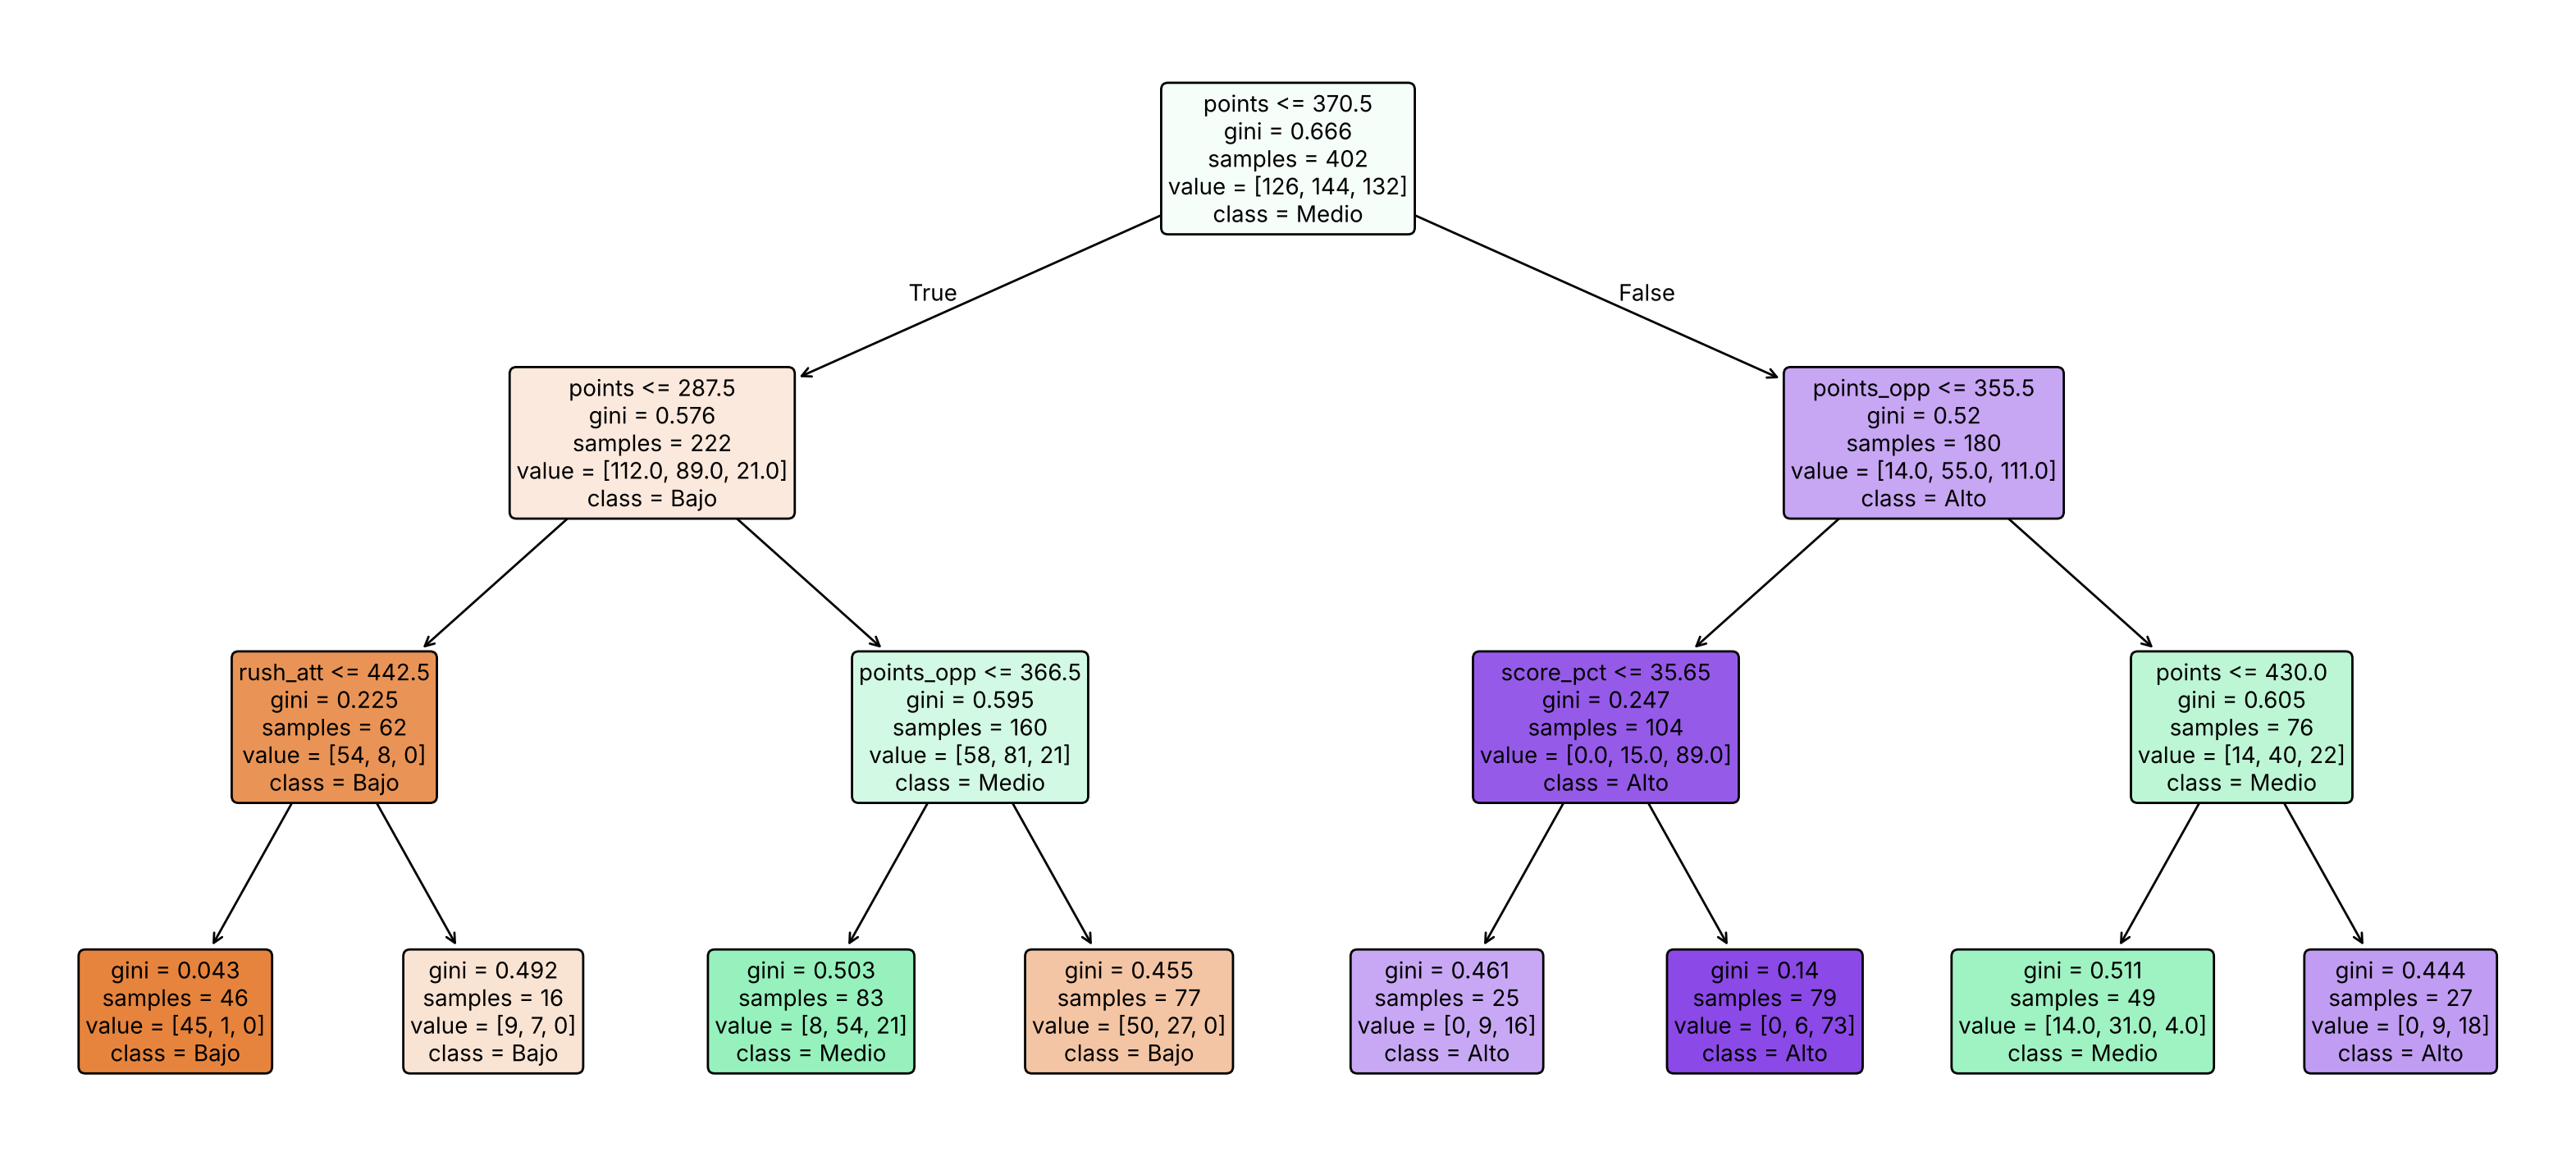

In [ ]:
plt.figure(figsize=(20, 9))
plot_tree(clf_dt_podado, feature_names=variables, class_names=clases,
          filled=True, rounded=True, fontsize=10)
plt.show()

### **Importancia de las variables**

Tanto el árbol como el bosque aleatorio permiten saber qué variables influyeron más en las predicciones (`feature_importances_`). Entre mayor es el valor, más importante fue la variable. Todos los valores suman 1.

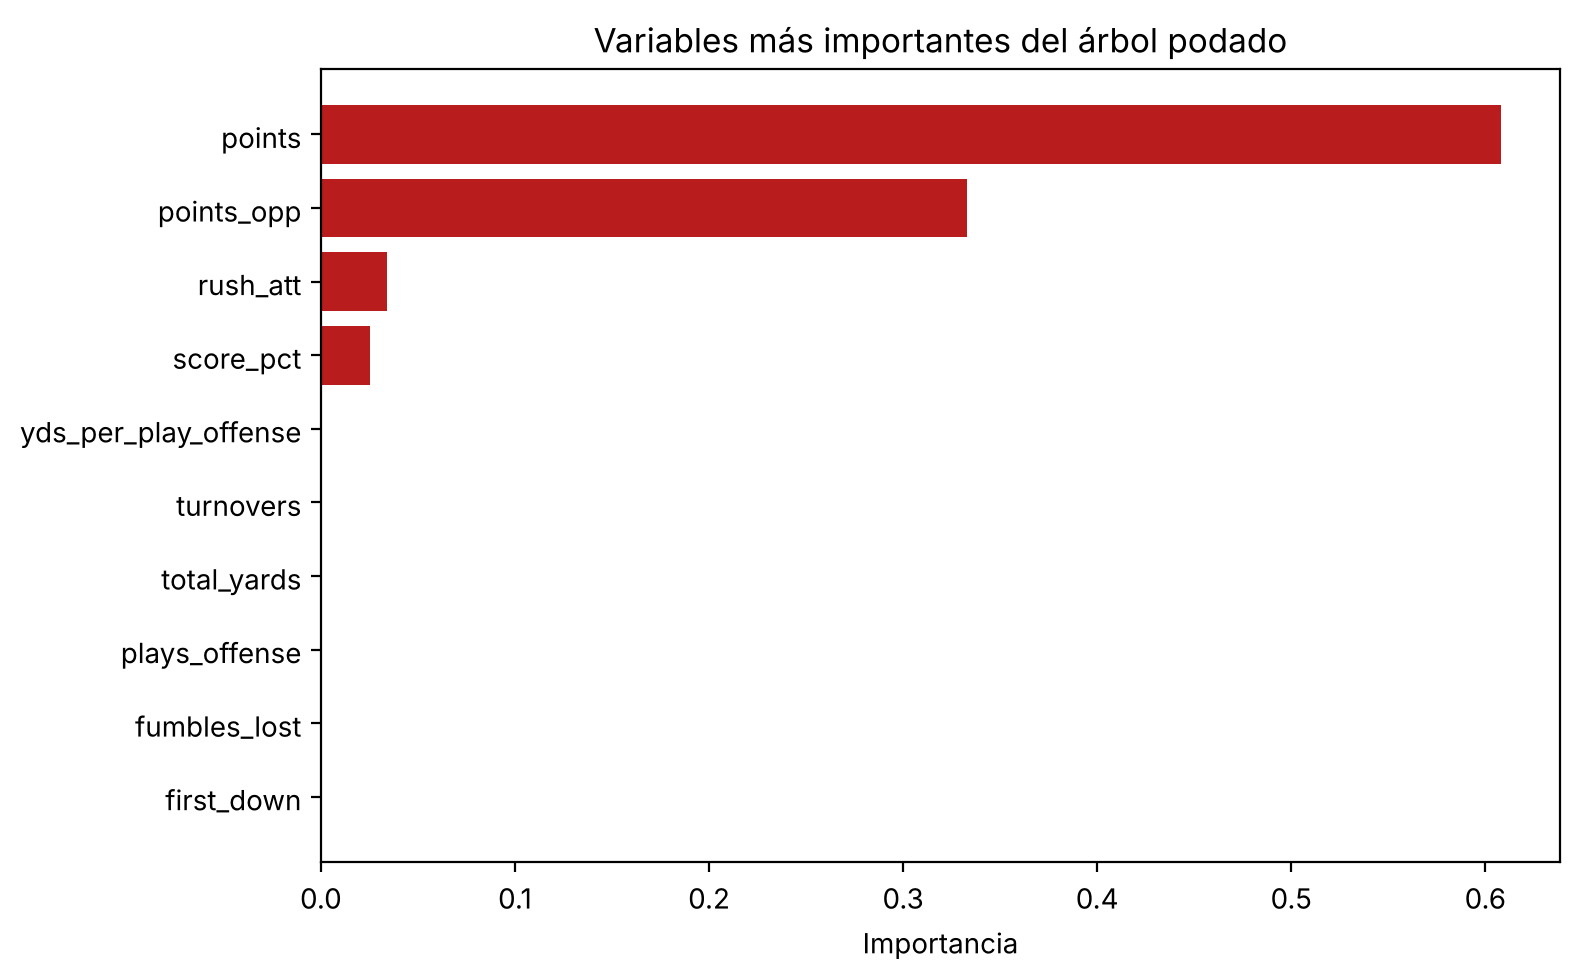

In [ ]:
importancia_dt = pd.Series(clf_dt_podado.feature_importances_, index=variables)
top_dt = importancia_dt.sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(top_dt.index, top_dt.values, color="#b91c1c")
plt.title("Variables más importantes del árbol podado")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

Casi toda la importancia del árbol podado está en dos variables: los puntos anotados (`points`, aproximadamente 0.61) y los puntos recibidos (`points_opp`, aproximadamente 0.33). Esto es razonable, porque ganar partidos depende directamente de anotar más puntos que el rival. Las demás variables casi no se usan porque el árbol solo tiene tres niveles.

## **Parte 2: Bosque aleatorio**

Un bosque aleatorio entrena muchos árboles de decisión y combina sus respuestas por votación. Cada árbol se entrena con una muestra distinta de los datos y, en cada división, solo considera una parte de las variables. Como los errores de cada árbol son distintos, al juntarlos el resultado suele ser más estable y se sobreentrena menos que un árbol individual.

Primero se entrena un bosque con los hiperparámetros predeterminados.

Exactitud en el conjunto de entrenamiento: 1.00
Exactitud en el conjunto de validación: 0.79

[[37  5  0]
 [ 8 35  5]
 [ 0 10 35]]


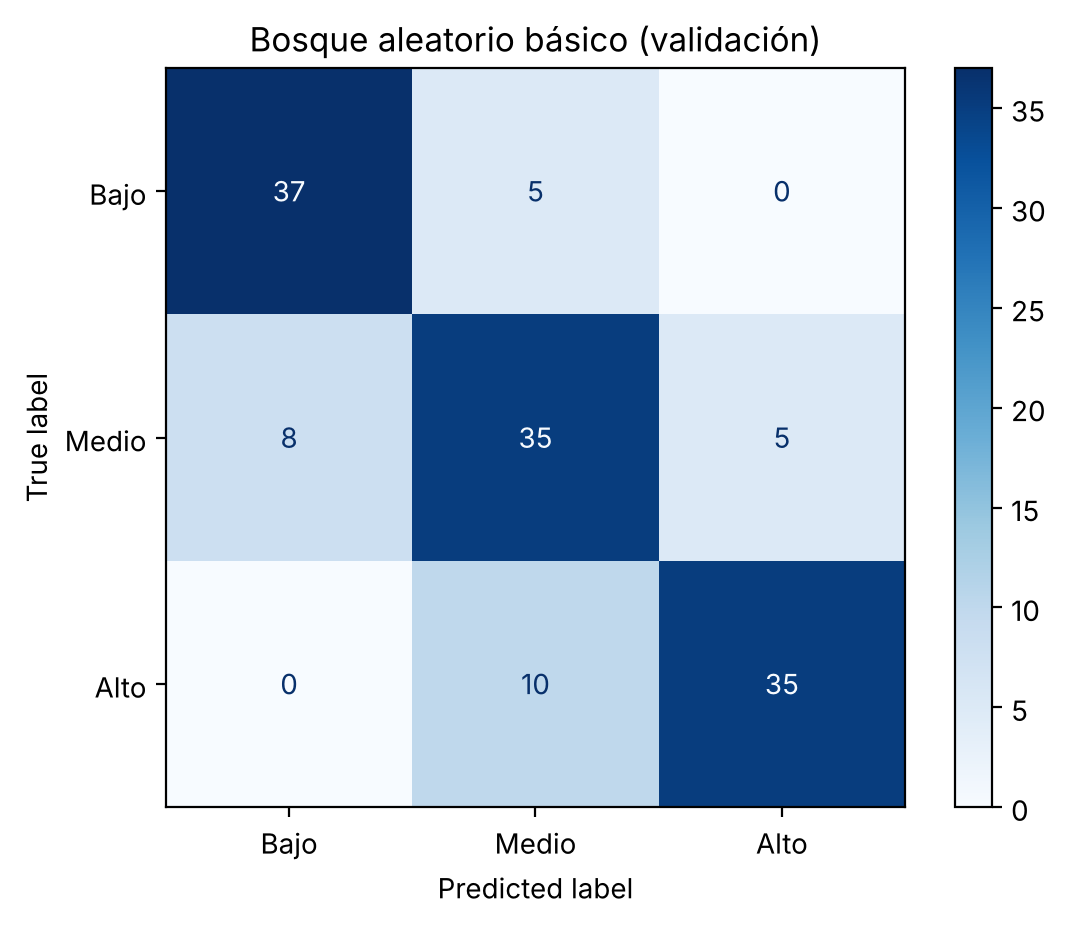

In [ ]:
modeloRF = RandomForestClassifier(random_state=1)
clf_rf = modeloRF.fit(X_train, y_train)

pred_rf = clf_rf.predict(X_val)
print('Exactitud en el conjunto de entrenamiento: %.2f' % clf_rf.score(X_train, y_train))
print('Exactitud en el conjunto de validación: %.2f' % clf_rf.score(X_val, y_val))
print()
print(confusion_matrix(y_val, pred_rf))

ConfusionMatrixDisplay.from_predictions(y_val, pred_rf, display_labels=clases, cmap="Blues")
plt.title("Bosque aleatorio básico (validación)")
plt.show()

El bosque aleatorio básico logra una exactitud de 0.79 en validación, mejor que el árbol completo (0.70) y que el árbol podado (0.72). También obtiene 1.00 en entrenamiento, por lo que sigue ajustándose mucho a esos datos, pero combinar muchos árboles compensa ese efecto y le da mejores resultados con datos nuevos. De los 135 equipos de validación, acertó en 107. Igual que el árbol, sus errores son entre niveles vecinos y nunca confundió un equipo bajo con uno alto.

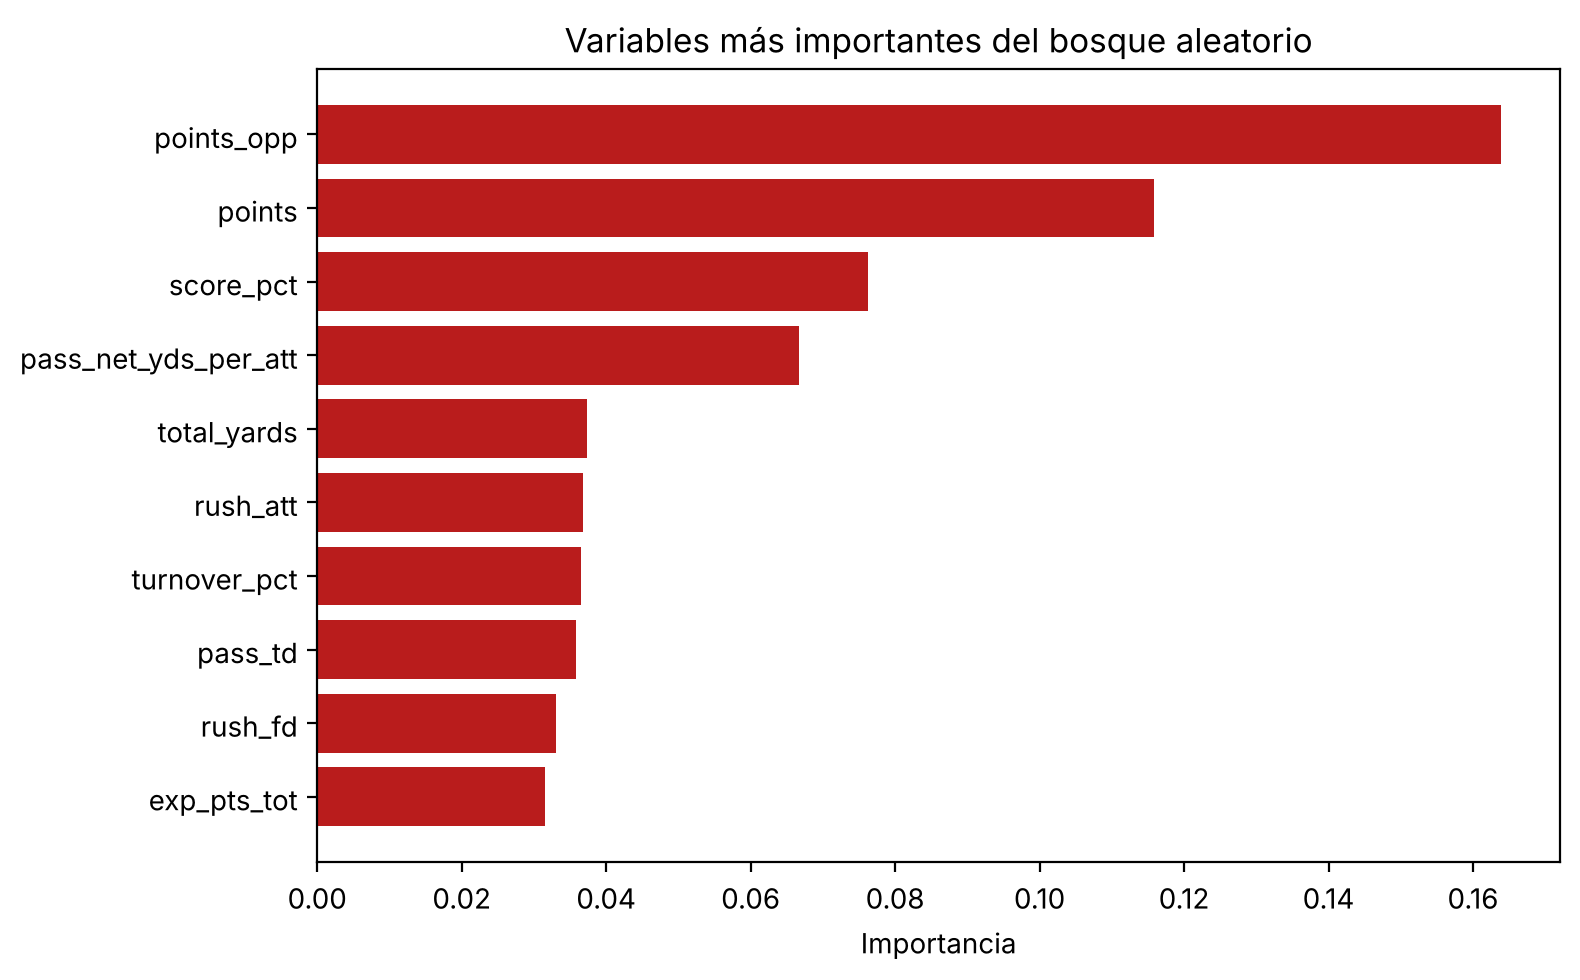

In [ ]:
importancia_rf = pd.Series(clf_rf.feature_importances_, index=variables)
top_rf = importancia_rf.sort_values(ascending=False).head(10).sort_values()

plt.figure(figsize=(8, 5))
plt.barh(top_rf.index, top_rf.values, color="#b91c1c")
plt.title("Variables más importantes del bosque aleatorio")
plt.xlabel("Importancia")
plt.tight_layout()
plt.show()

En el bosque la importancia está repartida entre más variables. Siguen siendo las más importantes los puntos recibidos (`points_opp`, aproximadamente 0.16) y los puntos anotados (`points`, aproximadamente 0.12), pero también aparecen el porcentaje de series de ataque que terminan en puntos (`score_pct`) y las yardas netas por pase intentado (`pass_net_yds_per_att`). Esto ocurre porque cada árbol del bosque ve solo una parte de las variables, así que el modelo aprovecha información que un solo árbol pequeño deja de lado.

### **Ajuste de hiperparámetros del bosque**

Igual que con el árbol, se pueden limitar los árboles del bosque para reducir el sobreentrenamiento. Estos son los hiperparámetros que se ajustan:

- `n_estimators`: número de árboles del bosque.
- `max_depth`, `min_samples_split` y `min_samples_leaf`: limitan el crecimiento de cada árbol, igual que en la Parte 1.
- `max_features`: cuántas variables se consideran en cada división. Con `'sqrt'` se usa la raíz cuadrada del total de variables.
- `bootstrap`: si es `True`, cada árbol se entrena con una muestra con reemplazo de los datos de entrenamiento.
- `oob_score`: si es `True`, se calcula la exactitud con los datos que cada árbol no usó (*out-of-bag*), lo que da una estimación adicional sin usar el conjunto de validación.
- `n_jobs`: número de procesadores a usar. Con `-1` se usan todos.

In [ ]:
modeloRF2 = RandomForestClassifier(n_estimators=300,
                                   criterion='gini',
                                   max_depth=8,
                                   min_samples_split=4,
                                   min_samples_leaf=2,
                                   max_features='sqrt',
                                   bootstrap=True,
                                   oob_score=True,
                                   n_jobs=-1,
                                   random_state=1)
clf_rf2 = modeloRF2.fit(X_train, y_train)

print('Exactitud en el conjunto de entrenamiento: %.2f' % clf_rf2.score(X_train, y_train))
print('Exactitud estimada con datos fuera de la muestra (OOB): %.2f' % clf_rf2.oob_score_)
print('Exactitud en el conjunto de validación: %.2f' % clf_rf2.score(X_val, y_val))

Exactitud en el conjunto de entrenamiento: 0.99
Exactitud estimada con datos fuera de la muestra (OOB): 0.72
Exactitud en el conjunto de validación: 0.77


Con los hiperparámetros ajustados el bosque obtiene 0.77 en validación, un resultado muy parecido al del bosque básico (0.79). La diferencia de 0.02 equivale a unos 3 equipos de 135, por lo que no es suficiente para decir que uno sea realmente mejor que el otro. En este caso, limitar la profundidad a 8 y pedir un mínimo de 2 registros por hoja casi no cambió el ajuste, y el bosque con valores predeterminados ya funcionaba bien. La exactitud OOB (0.72) es un poco menor que la de validación, lo cual es normal porque cada estimación se calcula con una muestra distinta y pequeña.

### **Comparación de los modelos**

Se juntan los resultados de los cuatro modelos. La comparación se hace con la exactitud en validación, que es el conjunto que sirve para elegir.

In [ ]:
modelos = {
    "Árbol completo": clf_dt,
    "Árbol podado": clf_dt_podado,
    "Bosque aleatorio básico": clf_rf,
    "Bosque aleatorio ajustado": clf_rf2,
}

resumen = pd.DataFrame({
    "Entrenamiento": [m.score(X_train, y_train) for m in modelos.values()],
    "Validación": [m.score(X_val, y_val) for m in modelos.values()],
}, index=modelos.keys())
resumen["Diferencia"] = resumen["Entrenamiento"] - resumen["Validación"]
resumen.round(2)

,Entrenamiento,Validación,Diferencia
Árbol completo,1.00,0.70,0.30
Árbol podado,0.74,0.72,0.02
Bosque aleatorio básico,1.00,0.79,0.21
Bosque aleatorio ajustado,0.99,0.77,0.22


El árbol completo es el que más se sobreentrena (diferencia de 0.30). El árbol podado casi no se sobreentrena (diferencia de 0.02) y supera al árbol completo, pero acierta menos que los bosques. Los dos bosques tienen la mejor exactitud en validación, y el bosque básico queda en primer lugar con 0.79.

### **Evaluación final con el conjunto de prueba**

El conjunto de prueba no se ha usado para tomar ninguna decisión. Se elige el modelo con mejor exactitud en validación y solo ese se evalúa con los datos de prueba. Este resultado es la mejor estimación de cómo se comportaría el modelo con temporadas nuevas.

Modelo elegido: Bosque aleatorio básico
Exactitud en el conjunto de prueba: 0.75

[[36  6  0]
 [ 7 34  8]
 [ 2 11 31]]


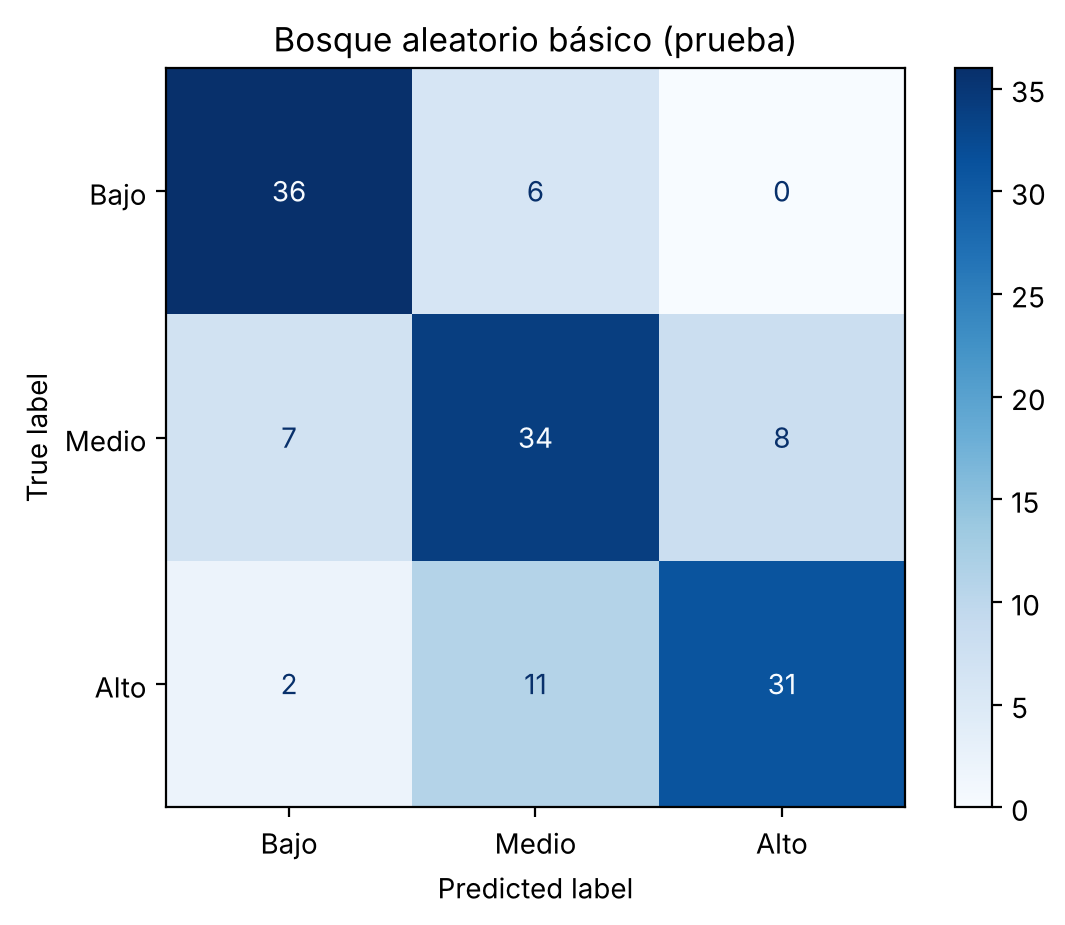

In [ ]:
mejor_nombre = resumen["Validación"].idxmax()
mejor_modelo = modelos[mejor_nombre]

pred_test = mejor_modelo.predict(X_test)
print("Modelo elegido:", mejor_nombre)
print('Exactitud en el conjunto de prueba: %.2f' % mejor_modelo.score(X_test, y_test))
print()
print(confusion_matrix(y_test, pred_test))

ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=clases, cmap="Blues")
plt.title(f"{mejor_nombre} (prueba)")
plt.show()

El modelo elegido, el bosque aleatorio básico, acierta en el 75 % de los equipos del conjunto de prueba (101 de 135). Es un poco menos que en validación (0.79), algo esperado, porque el modelo se eligió precisamente por su resultado en validación y los datos de prueba son completamente nuevos para él. Los errores se concentran otra vez en el nivel medio, y solo 2 equipos de rendimiento alto se clasificaron como bajos.

## **Conclusiones**

- Con las estadísticas de una temporada se puede predecir el nivel de rendimiento de un equipo con una exactitud cercana al 75 %, bastante por encima del 33 % que se lograría al azar.
- El árbol de decisión sin límites se sobreentrena. Al podarlo (`max_depth=3`, `min_samples_leaf=10`, `ccp_alpha=0.005`) deja de memorizar y su exactitud en validación mejora.
- El bosque aleatorio obtuvo los mejores resultados, porque combina muchos árboles y generaliza mejor que un árbol individual. El árbol podado, en cambio, es más fácil de explicar.
- Las variables más importantes son los puntos anotados y los puntos recibidos. Esto es lógico, pero también significa que el modelo describe bien una temporada ya jugada y no la anticipa.
- El nivel medio es el más difícil de clasificar, porque queda entre los otros dos.

**Limitaciones y posibles mejoras:**

- La división en entrenamiento, validación y prueba se hizo al azar, por lo que temporadas de un mismo equipo pueden quedar en conjuntos distintos. Una alternativa es entrenar con las primeras temporadas y probar con las más recientes.
- Para que el modelo realmente prediga, se podrían usar las estadísticas de la temporada anterior para anticipar el rendimiento de la siguiente.
- También se podría repetir el análisis sin `points` y `points_opp` para ver cuánto aportan las demás estadísticas.